In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
iris = load_iris()

In [3]:
# iris # X는 iris.data, y는 iris.target

In [4]:
X = iris.data

In [5]:
y = iris.target

In [6]:
X[:3] # [0:3] ==> 0은 포함, 3은 안포함 ==> [0,1,2], 3개 확인

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2]])

In [7]:
y # 정답

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [8]:
# df1 = load_iris(as_frame=True)
# df = df1.data.assign(species=iris.target_names[iris.target])
df = pd.DataFrame(data=iris.data, columns=iris.feature_names) # (데이터, 컬럼)
df['species'] = iris.target_names[iris.target] # 품종 = 품종_이름[각_품종의_인덱스]

print(df.shape)
print("결측치", df.isna().sum().sum())
df.describe().round(2)

(150, 5)
결측치 0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


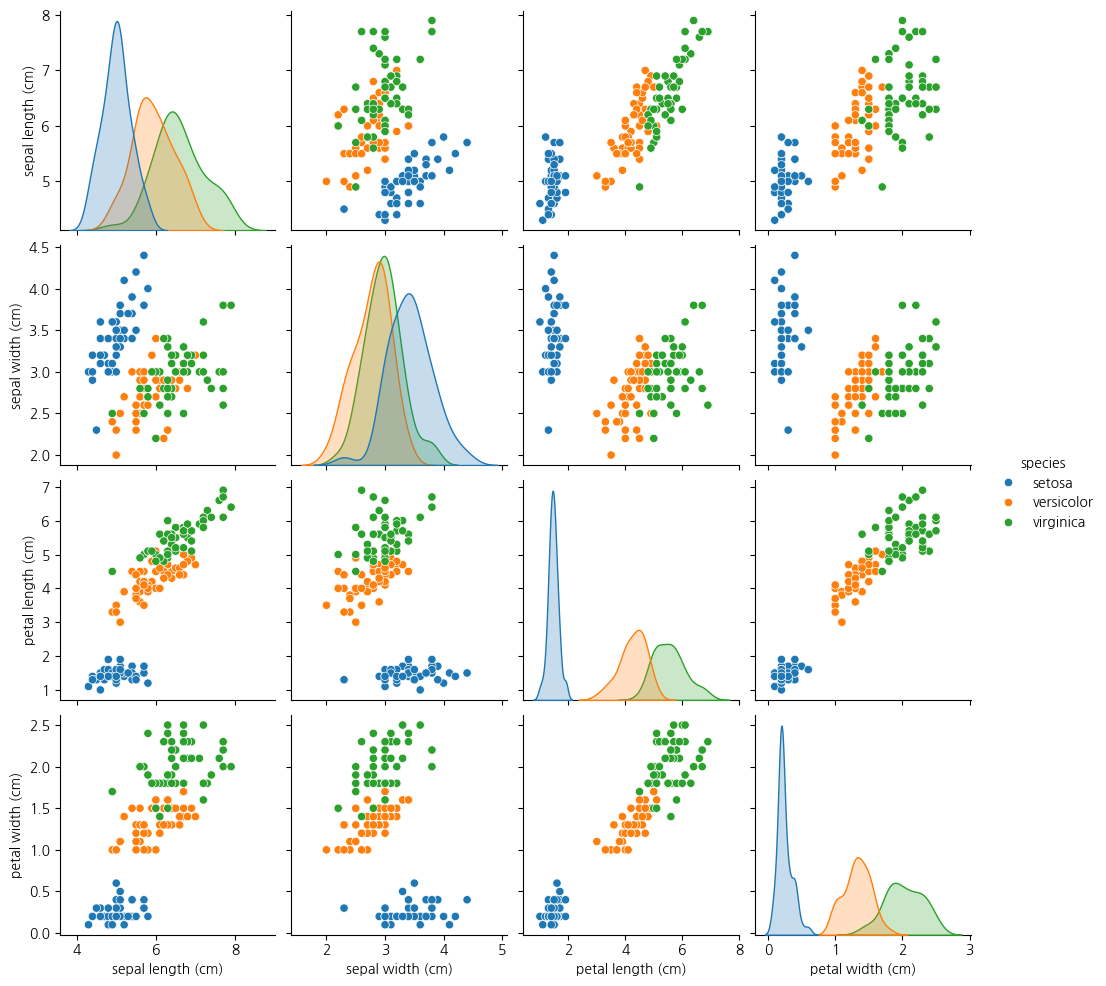

In [9]:
sns.pairplot(df, hue='species')
plt.show()

In [10]:
# ML 코딩 5단계
# 1. 훈련 데이터와 테스트 데이터로 나눈다. train_test_split 함수 사용
# 2. ML 알고리즘 선택. model = KNeighborsClassifier()
# 3. 훈련. model.fit(...)
# 4. 평가. model.score(...)
# 5. 새 데이터 예측. model.predict(...)

In [11]:
# X : 데이터, y : 정답, train : 훈련, test : 테스트
# 훈련_데이터, 테스트_데이터, 훈련_정답, 테스트_정답 = train_test_split(...)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [12]:
model = KNeighborsClassifier() # 붕어빵 = 틀()

In [13]:
model.fit(X_train, y_train) # 홍길동.공부해(문제지, 답안지)

KNeighborsClassifier()

In [14]:
print("훈련 점수:", model.score(X_train, y_train))
print("테스트 점수:", model.score(X_test, y_test))

훈련 점수: 0.9666666666666667
테스트 점수: 1.0


In [15]:
import mglearn

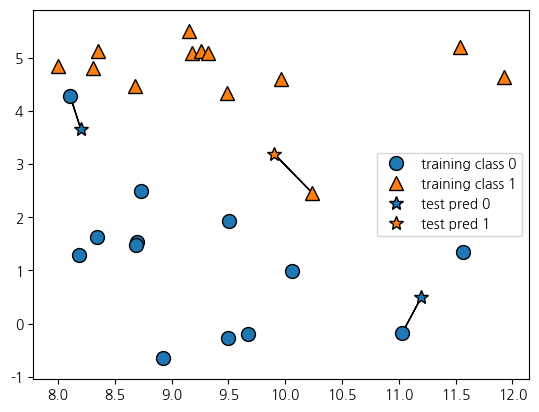

In [16]:
mglearn.plots.plot_knn_classification(n_neighbors=1) # 숫자가 작으면 overfitting, 크면 under...

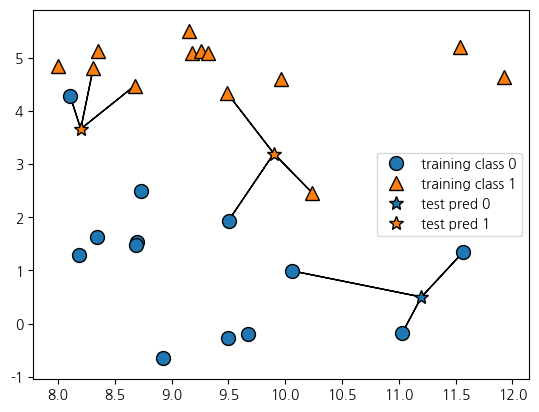

In [17]:
mglearn.plots.plot_knn_classification(n_neighbors=3) # 튜닝 성공

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = KNeighborsClassifier(n_neighbors=5) # 튜닝
model.fit(X_train, y_train)
print(f"훈련 점수: {model.score(X_train, y_train)*100:.1f}점")
print(f"테스트 점수: {model.score(X_test, y_test)*100:.1f}점")

훈련 점수: 96.7점
테스트 점수: 100.0점


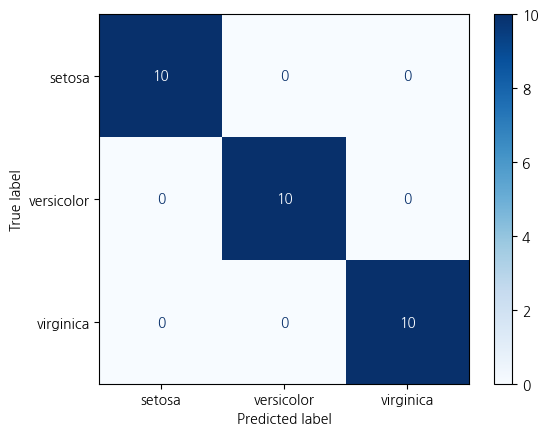

In [22]:
ConfusionMatrixDisplay.from_estimator(
    model, X_test, y_test, display_labels=iris.target_names, cmap='Blues'
)
plt.show()

In [23]:
# end